In [1]:
# Install dependensi tambahan yang belum ada di Colab
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm>=1.0.0'])
print('✅ timm siap')

✅ timm siap


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print('✅ Google Drive terpasang')

Mounted at /content/drive
✅ Google Drive terpasang


In [3]:
# Semua import dikumpulkan di satu cell
import copy
import importlib.util
import math
import os
import platform
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import timm
from timm.optim import param_groups_layer_decay
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from torchvision.datasets import ImageFolder

print('✅ Semua library berhasil diimport')
print(f'   Python  : {platform.python_version()}')
print(f'   PyTorch : {torch.__version__}')
print(f'   timm    : {timm.__version__}')

✅ Semua library berhasil diimport
   Python  : 3.13.16
   PyTorch : 2.11.0+cu130
   timm    : 1.0.30


In [4]:
# Cek ketersediaan GPU
print('=' * 50)
print(f'  CUDA tersedia : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'  GPU           : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM          : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('  ⚠️  Aktifkan GPU: Runtime → Change runtime type → T4 GPU')
print('=' * 50)

  CUDA tersedia : True
  GPU           : Tesla T4
  VRAM          : 15.6 GB


In [5]:
# CONFIG — semua konstanta di satu cell; sesuaikan path sebelum menjalankan

# ── Path ──────────────────────────────────────────────────────────────────
DRIVE_ROOT     = '/content/drive/MyDrive'
DATASET_ROOT   = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'train')    # folder asli
MY_TRAIN_DIR   = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'my_train') # dari NB03
MY_VAL_DIR     = os.path.join(DRIVE_ROOT, 'dataset_sampah', 'my_val')   # dari NB03
CKPT_DIR       = '/content/checkpoints'
SUBMISSION_DIR = '/content/submission_nb08'

# ── Dataset ───────────────────────────────────────────────────────────────
CLASSES     = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
NUM_CLASSES = len(CLASSES)
VAL_FRAC    = 0.15
SEED        = 42

# ── 4 Model NB08 ──────────────────────────────────────────────────────────
CONVNEXT_S = 'convnext_small.fb_in22k_ft_in1k'
SWIN_S     = 'swin_small_patch4_window7_224.ms_in22k_ft_in1k'

MODEL_CONFIGS = [
    {'tag': 'm1_convnext_small_std',  'name': CONVNEXT_S, 'llrd': False},
    {'tag': 'm2_convnext_small_llrd', 'name': CONVNEXT_S, 'llrd': True },
    {'tag': 'm3_swin_small_std',      'name': SWIN_S,     'llrd': False},
    {'tag': 'm4_swin_small_llrd',     'name': SWIN_S,     'llrd': True },
]

# ── Input ─────────────────────────────────────────────────────────────────
IMG_SIZE      = 224
RESIZE_SIZE   = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── DataLoader ────────────────────────────────────────────────────────────
BATCH_SIZE  = 32
GRAD_ACCUM  = 2
NUM_WORKERS = 2

# ── Phase 1 (head saja) ───────────────────────────────────────────────────
P1_EPOCHS  = 3
P1_LR_HEAD = 1e-3

# ── Phase 2 (full fine-tune) ──────────────────────────────────────────────
P2_EPOCHS      = 25
P2_LR_BACKBONE = 1e-4
P2_LR_HEAD     = 1e-3
WEIGHT_DECAY   = 0.05
WARMUP_EPOCHS  = 1
LLRD_DECAY     = 0.85

# ── Regularisasi ──────────────────────────────────────────────────────────
LABEL_SMOOTH   = 0.1
DROP_PATH_STD  = 0.1
DROP_PATH_LLRD = 0.2
EMA_DECAY      = 0.995
MIXUP_ALPHA    = 0.8
CUTMIX_ALPHA   = 1.0
MIXUP_PROB     = 0.5

# ── Reproduksibilitas & device ────────────────────────────────────────────
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(CKPT_DIR,       exist_ok=True)
os.makedirs(SUBMISSION_DIR, exist_ok=True)

print(f'Device        : {DEVICE}')
print(f'Batch efektif : {BATCH_SIZE * GRAD_ACCUM}')
print(f'Phase 2       : {P2_EPOCHS} epoch')
print()
print('4 model yang akan dilatih:')
for cfg in MODEL_CONFIGS:
    resep = 'LLRD' if cfg['llrd'] else 'Standard'
    print(f'  {cfg["tag"]:<30} {cfg["name"]}  [{resep}]')

Device        : cuda
Batch efektif : 64
Phase 2       : 25 epoch

4 model yang akan dilatih:
  m1_convnext_small_std          convnext_small.fb_in22k_ft_in1k  [Standard]
  m2_convnext_small_llrd         convnext_small.fb_in22k_ft_in1k  [LLRD]
  m3_swin_small_std              swin_small_patch4_window7_224.ms_in22k_ft_in1k  [Standard]
  m4_swin_small_llrd             swin_small_patch4_window7_224.ms_in22k_ft_in1k  [LLRD]


In [6]:
if os.path.isdir(MY_TRAIN_DIR) and os.path.isdir(MY_VAL_DIR):
    TRAIN_DIR = MY_TRAIN_DIR
    VAL_DIR   = MY_VAL_DIR
    print('✅ Split dari Drive dipakai langsung')
    print(f'   TRAIN_DIR : {TRAIN_DIR}')
    print(f'   VAL_DIR   : {VAL_DIR}')
else:
    TRAIN_DIR = '/content/my_train'
    VAL_DIR   = '/content/my_val'
    print('⚠️  Split belum ada — membuat split baru ...')
    for d in [TRAIN_DIR, VAL_DIR]:
        os.makedirs(d, exist_ok=True)
        for cls in CLASSES:
            os.makedirs(os.path.join(d, cls), exist_ok=True)
    for cls in CLASSES:
        src  = os.path.join(DATASET_ROOT, cls)
        imgs = sorted(os.listdir(src))
        tr, vl = train_test_split(imgs, test_size=VAL_FRAC, random_state=SEED)
        for f in tr:
            shutil.copy2(os.path.join(src, f), os.path.join(TRAIN_DIR, cls, f))
        for f in vl:
            shutil.copy2(os.path.join(src, f), os.path.join(VAL_DIR, cls, f))
    print(f'✅ Split selesai (seed={SEED}, val={VAL_FRAC:.0%})')

# Ringkasan jumlah gambar per kelas
print(f'\n{"Kelas":<22} {"train":>8} {"val":>6}')
print('-' * 38)
total_tr = total_vl = 0
for cls in CLASSES:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    n_vl = len(os.listdir(os.path.join(VAL_DIR,   cls)))
    total_tr += n_tr
    total_vl += n_vl
    print(f'  {cls:<20} {n_tr:>8} {n_vl:>6}')
print('-' * 38)
print(f'  {"Total":<20} {total_tr:>8} {total_vl:>6}')

✅ Split dari Drive dipakai langsung
   TRAIN_DIR : /content/drive/MyDrive/dataset_sampah/my_train
   VAL_DIR   : /content/drive/MyDrive/dataset_sampah/my_val

Kelas                     train    val
--------------------------------------
  botol_plastik             445     78
  gelas_plastik             443     78
  kertas_kardus             311     54
  saset_kemasan             573    100
  styrofoam                 571    100
--------------------------------------
  Total                    2343    410


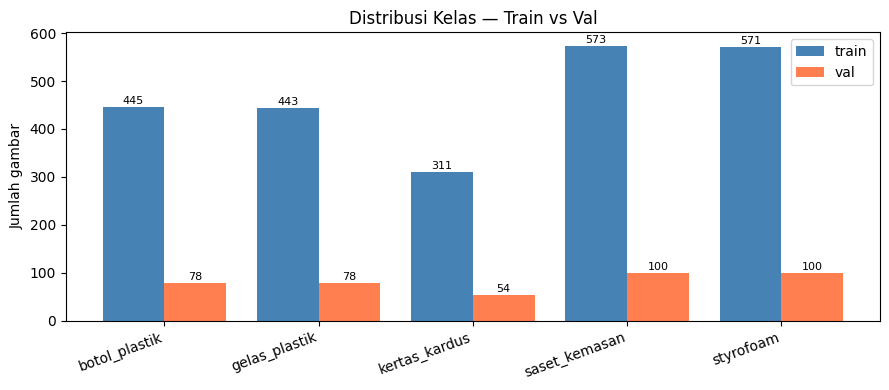

In [7]:
# Visualisasi distribusi kelas train vs val
counts_tr = [len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in CLASSES]
counts_vl = [len(os.listdir(os.path.join(VAL_DIR,   c))) for c in CLASSES]
x = range(NUM_CLASSES)

fig, ax = plt.subplots(figsize=(9, 4))
b1 = ax.bar([i - 0.2 for i in x], counts_tr, 0.4, label='train', color='steelblue')
b2 = ax.bar([i + 0.2 for i in x], counts_vl, 0.4, label='val',   color='coral')
ax.set_xticks(list(x))
ax.set_xticklabels(CLASSES, rotation=20, ha='right')
ax.set_ylabel('Jumlah gambar')
ax.set_title('Distribusi Kelas — Train vs Val')
ax.legend()
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Definisi transform train (augmentasi kuat) dan val (deterministik)
def get_train_transform():
    """RandomResizedCrop + TrivialAugment + RandomErasing."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
        transforms.TrivialAugmentWide(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.35, scale=(0.02, 0.2)),
    ])


def get_val_transform():
    """Identik dengan get_transform() di submission: Resize(256) + CenterCrop(224)."""
    return transforms.Compose([
        transforms.Resize(RESIZE_SIZE),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])


train_tf = get_train_transform()
val_tf   = get_val_transform()
print(f'✅ Train : {len(train_tf.transforms)} transform')
print(f'   Val   : {len(val_tf.transforms)} transform')

✅ Train : 7 transform
   Val   : 4 transform


In [9]:
# Dataset, WeightedRandomSampler, dan DataLoader
train_ds = ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds   = ImageFolder(VAL_DIR,   transform=val_tf)

# Bobot per sampel — kelas lebih sedikit mendapat bobot lebih besar
class_counts   = np.array([len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in train_ds.classes])
class_w        = 1.0 / class_counts
sample_weights = np.array([class_w[lbl] for _, lbl in train_ds.samples])
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

# Bobot loss — inverse frequency, dinormalisasi ke skala NUM_CLASSES
loss_weights = torch.tensor(
    class_w / class_w.sum() * NUM_CLASSES, dtype=torch.float32
).to(DEVICE)

print(f'Train : {len(train_ds)} gambar | {len(train_loader)} batch')
print(f'Val   : {len(val_ds)} gambar | {len(val_loader)} batch')
print(f'Kelas : {train_ds.classes}')
print(f'Loss weight (inv-freq): {[f"{w:.3f}" for w in loss_weights.cpu().tolist()]}')

Train : 2343 gambar | 74 batch
Val   : 410 gambar | 13 batch
Kelas : ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
Loss weight (inv-freq): ['1.002', '1.006', '1.433', '0.778', '0.781']


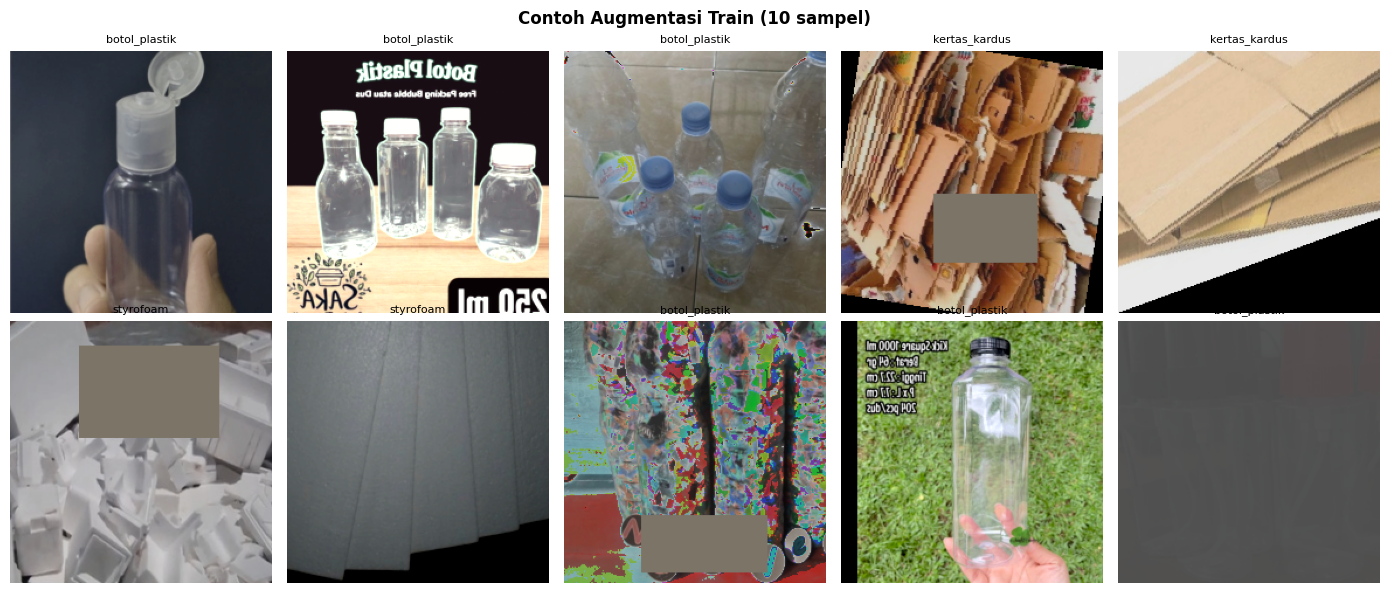

In [10]:
# Visualisasi 10 contoh augmentasi train
MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD_T  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    """Denormalisasi tensor gambar untuk ditampilkan."""
    return (t * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()


imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Contoh Augmentasi Train (10 sampel)', fontsize=12, fontweight='bold')
for ax, img, lbl in zip(axes.flat, imgs[:10], labels[:10]):
    ax.imshow(denorm(img))
    ax.set_title(train_ds.classes[lbl], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
# EMA, Mixup/CutMix, dan soft-label cross-entropy dengan class weight

class EMA:
    """Exponential Moving Average bobot model — checkpoint lebih stabil."""
    def __init__(self, model, decay=EMA_DECAY):
        self.decay  = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for s, m in zip(self.shadow.parameters(), model.parameters()):
            s.data = self.decay * s.data + (1 - self.decay) * m.data

    def model(self):
        return self.shadow


def rand_bbox(size, lam):
    """Koordinat kotak acak untuk CutMix."""
    W, H   = size[2], size[3]
    cut    = math.sqrt(1 - lam)
    cw, ch = int(W * cut), int(H * cut)
    cx, cy = np.random.randint(W), np.random.randint(H)
    return (max(0, cx - cw // 2), max(0, cy - ch // 2),
            min(W, cx + cw // 2), min(H, cy + ch // 2))


def get_batch_mix(imgs, labels, n_cls=NUM_CLASSES):
    """Terapkan Mixup atau CutMix secara acak; kembalikan (imgs, soft_labels)."""
    if np.random.rand() > MIXUP_PROB:
        oh = torch.zeros(len(labels), n_cls, device=imgs.device)
        return imgs, oh.scatter_(1, labels.unsqueeze(1), 1)
    idx = torch.randperm(len(imgs), device=imgs.device)
    if np.random.rand() < 0.5:       # Mixup
        lam  = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)
        imgs = lam * imgs + (1 - lam) * imgs[idx]
    else:                             # CutMix
        lam          = np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
        x1, y1, x2, y2 = rand_bbox(imgs.size(), lam)
        imgs[:, :, x1:x2, y1:y2] = imgs[idx, :, x1:x2, y1:y2]
        lam = 1 - (x2 - x1) * (y2 - y1) / (imgs.size(2) * imgs.size(3))
    oh_a = torch.zeros(len(labels), n_cls, device=imgs.device).scatter_(1, labels.unsqueeze(1), 1)
    oh_b = torch.zeros(len(labels), n_cls, device=imgs.device).scatter_(1, labels[idx].unsqueeze(1), 1)
    return imgs, lam * oh_a + (1 - lam) * oh_b


def soft_ce_loss(logits, soft_labels, weight=None, smooth=LABEL_SMOOTH):
    """Cross-entropy dengan soft targets + label smoothing + opsional class weight."""
    n  = logits.size(1)
    sl = soft_labels * (1 - smooth) + smooth / n
    lp = nn.functional.log_softmax(logits, dim=1)
    if weight is not None:
        return -(sl * lp * weight.unsqueeze(0)).sum(dim=1).mean()
    return -(sl * lp).sum(dim=1).mean()


print('✅ EMA, Mixup/CutMix, soft_ce_loss siap')

✅ EMA, Mixup/CutMix, soft_ce_loss siap


In [12]:
# Loop train dan evaluasi satu epoch

def train_epoch(model, loader, optimizer, scaler, ema=None, scheduler=None, accum=GRAD_ACCUM):
    """Train satu epoch dengan AMP, gradient accumulation, clip norm, EMA opsional."""
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()
    for step, (imgs, labels) in enumerate(loader):
        imgs, labels   = imgs.to(DEVICE), labels.to(DEVICE)
        imgs, soft_lbl = get_batch_mix(imgs, labels)
        with torch.autocast(device_type='cuda', dtype=torch.float16,
                            enabled=torch.cuda.is_available()):
            loss = soft_ce_loss(model(imgs), soft_lbl, weight=loss_weights) / accum
        scaler.scale(loss).backward()
        if (step + 1) % accum == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            if ema:       ema.update(model)
            if scheduler: scheduler.step()
        total_loss += loss.item() * accum
    return total_loss / len(loader)


@torch.no_grad()
def eval_epoch(model, loader):
    """Hitung Macro-F1 dan akurasi pada satu DataLoader."""
    model.eval()
    preds, truths = [], []
    for imgs, labels in loader:
        preds.extend(model(imgs.to(DEVICE)).argmax(1).cpu().tolist())
        truths.extend(labels.tolist())
    f1  = f1_score(truths, preds, average='macro', zero_division=0)
    acc = sum(p == t for p, t in zip(preds, truths)) / len(truths)
    return f1, acc


print('✅ train_epoch, eval_epoch siap')

✅ train_epoch, eval_epoch siap


In [13]:
# Build model, freeze/unfreeze backbone, optimizer standar & LLRD, scheduler

def _is_head(name):
    # Cek level pertama nama parameter saja
    # 'fc' sengaja dihapus — terlalu broad, match mlp.fc1/fc2 di dalam blok ConvNeXt
    return name.split('.')[0] in ('head', 'classifier')


def build_model(model_name, drop_path):
    """Buat model timm pretrained, pindah ke DEVICE."""
    model = timm.create_model(model_name, pretrained=True,
                              num_classes=NUM_CLASSES, drop_path_rate=drop_path)
    model = model.to(DEVICE)
    if torch.cuda.is_available():
        model = model.to(memory_format=torch.channels_last)
    n = sum(p.numel() for p in model.parameters()) / 1e6
    print(f'  {model_name}  ({n:.1f}M param, drop_path={drop_path})')
    return model


def freeze_backbone(model):
    """Bekukan semua layer kecuali head classifier."""
    for name, p in model.named_parameters():
        p.requires_grad_(_is_head(name))
    n = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f'    Trainable: {n:.3f}M (head saja)')


def unfreeze_all(model):
    """Aktifkan semua parameter untuk full fine-tuning."""
    for p in model.parameters():
        p.requires_grad_(True)


def make_optimizer_standard(model):
    """AdamW: backbone LR=1e-4, head LR=1e-3."""
    head_p     = [p for n, p in model.named_parameters() if _is_head(n) and p.requires_grad]
    backbone_p = [p for n, p in model.named_parameters() if not _is_head(n) and p.requires_grad]
    return torch.optim.AdamW(
        [{'params': backbone_p, 'lr': P2_LR_BACKBONE},
         {'params': head_p,     'lr': P2_LR_HEAD}],
        weight_decay=WEIGHT_DECAY
    )


def make_optimizer_llrd(model, decay=LLRD_DECAY, base_lr=P2_LR_BACKBONE):
    """AdamW dengan Layer-wise LR Decay — LR mengecil dari head ke stem."""
    try:
        groups = param_groups_layer_decay(model, weight_decay=WEIGHT_DECAY, layer_decay=decay)
        for g in groups:
            g['lr'] = g.get('lr_scale', 1.0) * base_lr
        opt = torch.optim.AdamW(groups, lr=base_lr)
        print(f'    LLRD via timm — {len(groups)} param groups')
    except Exception:
        # Fallback manual LLRD
        named = list(model.named_parameters())
        groups = []
        for i, (name, p) in enumerate(named):
            if not p.requires_grad: continue
            lr_i = base_lr * (decay ** (len(named) - i - 1))
            wd   = 0.0 if ('bias' in name or 'norm' in name) else WEIGHT_DECAY
            groups.append({'params': [p], 'lr': lr_i, 'weight_decay': wd})
        opt = torch.optim.AdamW(groups)
        print(f'    LLRD manual — {len(groups)} param groups')
    return opt


def make_scheduler(optimizer, total_steps, warmup_steps):
    """Linear warmup + cosine decay per langkah optimizer."""
    def lr_lambda(step):
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.0, 0.5 * (1 + math.cos(math.pi * prog)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


print('✅ build_model, optimizer, scheduler siap')

✅ build_model, optimizer, scheduler siap


In [14]:
# Fungsi training lengkap (Phase 1 + Phase 2) dan plotting kurva

def train_full(cfg):
    """Latih satu model (Phase 1: head + Phase 2: full); simpan checkpoint terbaik."""
    tag       = cfg['tag']
    use_llrd  = cfg['llrd']
    drop      = DROP_PATH_LLRD if use_llrd else DROP_PATH_STD
    resep     = 'LLRD' if use_llrd else 'Standard'
    best_path = os.path.join(CKPT_DIR, f'{tag}_best.pth')
    history   = {'loss': [], 'f1': [], 'f1_ema': []}
    best_f1   = 0.0

    print(f'\n{"="*60}')
    print(f'  {tag}  |  resep: {resep}  |  drop_path: {drop}')
    print(f'{"="*60}')

    model  = build_model(cfg['name'], drop)
    scaler = torch.GradScaler(enabled=torch.cuda.is_available())
    ema    = EMA(model)

    # Phase 1 — head saja
    print(f'\n  Phase 1 — head only ({P1_EPOCHS} epoch)')
    freeze_backbone(model)
    opt1   = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=P1_LR_HEAD, weight_decay=WEIGHT_DECAY
    )
    sched1 = make_scheduler(opt1, P1_EPOCHS * len(train_loader), warmup_steps=0)
    for ep in range(1, P1_EPOCHS + 1):
        loss      = train_epoch(model, train_loader, opt1, scaler, ema=ema, scheduler=sched1)
        f1, _     = eval_epoch(model, val_loader)
        f1_ema, _ = eval_epoch(ema.model(), val_loader)
        history['loss'].append(loss)
        history['f1'].append(f1)
        history['f1_ema'].append(f1_ema)
        print(f'  Ep {ep:02}/{P1_EPOCHS} | loss {loss:.4f} | F1 {f1:.4f} | F1-EMA {f1_ema:.4f}')

    # Phase 2 — semua layer
    print(f'\n  Phase 2 — full fine-tune ({P2_EPOCHS} epoch, {resep})')
    unfreeze_all(model)
    opt2   = make_optimizer_llrd(model) if use_llrd else make_optimizer_standard(model)
    sched2 = make_scheduler(opt2, P2_EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader))
    for ep in range(1, P2_EPOCHS + 1):
        loss      = train_epoch(model, train_loader, opt2, scaler, ema=ema, scheduler=sched2)
        f1, _     = eval_epoch(model, val_loader)
        f1_ema, _ = eval_epoch(ema.model(), val_loader)
        cur       = max(f1, f1_ema)
        if cur > best_f1:
            best_f1 = cur
            torch.save((ema.model() if f1_ema >= f1 else model).state_dict(), best_path)
        history['loss'].append(loss)
        history['f1'].append(f1)
        history['f1_ema'].append(f1_ema)
        mark = ' ✓' if cur == best_f1 else ''
        print(f'  Ep {ep:02}/{P2_EPOCHS} | loss {loss:.4f} | F1 {f1:.4f} | '
              f'F1-EMA {f1_ema:.4f} | best {best_f1:.4f}{mark}')

    print(f'\n✅ {tag} — Best F1: {best_f1:.4f} → {best_path}')
    return history, best_path, best_f1


def plot_history(history, tag):
    """Plot kurva train loss dan val F1 (biasa + EMA)."""
    epochs = range(1, len(history['loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Training Curve — {tag}', fontweight='bold')
    ax1.plot(epochs, history['loss'], 'b-o', ms=3)
    ax1.axvline(P1_EPOCHS + 0.5, color='gray', ls='--', alpha=0.5, label='Phase 2 mulai')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title('Train Loss')
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history['f1'],     'g-o',  ms=3, label='Val F1')
    ax2.plot(epochs, history['f1_ema'], 'r--o', ms=3, label='Val F1-EMA')
    ax2.axvline(P1_EPOCHS + 0.5, color='gray', ls='--', alpha=0.5)
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Macro-F1'); ax2.set_title('Validation F1')
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Peak F1     : {max(history["f1"]):.4f}')
    print(f'  Peak F1-EMA : {max(history["f1_ema"]):.4f}')


print('✅ train_full, plot_history siap')

✅ train_full, plot_history siap


## Training 4 Model

| Model | Backbone | Resep | Drop Path | Estimasi waktu T4 |
|---|---|---|---|---|
| M1 | ConvNeXt-Small | Standard | 0.1 | ~25 menit |
| M2 | ConvNeXt-Small | LLRD 0.85 | 0.2 | ~25 menit |
| M3 | Swin-Small | Standard | 0.1 | ~25 menit |
| M4 | Swin-Small | LLRD 0.85 | 0.2 | ~25 menit |

In [15]:
# M1 — ConvNeXt-Small, resep standar
hist_m1, ckpt_m1, best_f1_m1 = train_full(MODEL_CONFIGS[0])


  m1_convnext_small_std  |  resep: Standard  |  drop_path: 0.1


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

  convnext_small.fb_in22k_ft_in1k  (49.5M param, drop_path=0.1)

  Phase 1 — head only (3 epoch)
    Trainable: 0.005M (head saja)
  Ep 01/3 | loss 0.9903 | F1 0.8993 | F1-EMA 0.4812
  Ep 02/3 | loss 0.8137 | F1 0.9186 | F1-EMA 0.7363
  Ep 03/3 | loss 0.7909 | F1 0.9293 | F1-EMA 0.8291

  Phase 2 — full fine-tune (25 epoch, Standard)


/tmp/ipykernel_2689/3191753487.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if scheduler: scheduler.step()


  Ep 01/25 | loss 0.8042 | F1 0.9267 | F1-EMA 0.8886 | best 0.9267 ✓
  Ep 02/25 | loss 0.6645 | F1 0.9243 | F1-EMA 0.8992 | best 0.9267
  Ep 03/25 | loss 0.7308 | F1 0.9262 | F1-EMA 0.9367 | best 0.9367 ✓
  Ep 04/25 | loss 0.6580 | F1 0.9453 | F1-EMA 0.9471 | best 0.9471 ✓
  Ep 05/25 | loss 0.6599 | F1 0.9354 | F1-EMA 0.9471 | best 0.9471 ✓
  Ep 06/25 | loss 0.7027 | F1 0.9565 | F1-EMA 0.9560 | best 0.9565 ✓
  Ep 07/25 | loss 0.6955 | F1 0.9575 | F1-EMA 0.9551 | best 0.9575 ✓
  Ep 08/25 | loss 0.6619 | F1 0.9519 | F1-EMA 0.9579 | best 0.9579 ✓
  Ep 09/25 | loss 0.6269 | F1 0.9543 | F1-EMA 0.9573 | best 0.9579
  Ep 10/25 | loss 0.6086 | F1 0.9562 | F1-EMA 0.9598 | best 0.9598 ✓
  Ep 11/25 | loss 0.6257 | F1 0.9642 | F1-EMA 0.9580 | best 0.9642 ✓
  Ep 12/25 | loss 0.6298 | F1 0.9598 | F1-EMA 0.9608 | best 0.9642
  Ep 13/25 | loss 0.6118 | F1 0.9543 | F1-EMA 0.9585 | best 0.9642
  Ep 14/25 | loss 0.6302 | F1 0.9579 | F1-EMA 0.9580 | best 0.9642
  Ep 15/25 | loss 0.6391 | F1 0.9586 | F1-EM

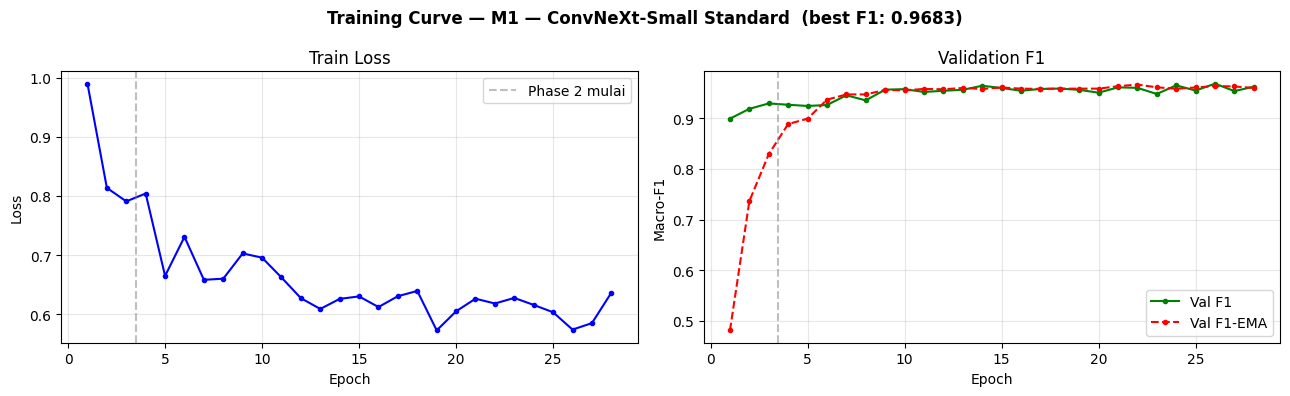

  Peak F1     : 0.9683
  Peak F1-EMA : 0.9665


In [16]:
plot_history(hist_m1, f'M1 — ConvNeXt-Small Standard  (best F1: {best_f1_m1:.4f})')

In [17]:
# M2 — ConvNeXt-Small, resep LLRD
hist_m2, ckpt_m2, best_f1_m2 = train_full(MODEL_CONFIGS[1])


  m2_convnext_small_llrd  |  resep: LLRD  |  drop_path: 0.2
  convnext_small.fb_in22k_ft_in1k  (49.5M param, drop_path=0.2)

  Phase 1 — head only (3 epoch)
    Trainable: 0.005M (head saja)
  Ep 01/3 | loss 1.1094 | F1 0.8957 | F1-EMA 0.3712
  Ep 02/3 | loss 0.7835 | F1 0.9060 | F1-EMA 0.6750
  Ep 03/3 | loss 0.8412 | F1 0.9033 | F1-EMA 0.8219

  Phase 2 — full fine-tune (25 epoch, LLRD)
    LLRD via timm — 76 param groups
  Ep 01/25 | loss 0.8329 | F1 0.9113 | F1-EMA 0.8715 | best 0.9113 ✓
  Ep 02/25 | loss 0.8341 | F1 0.9470 | F1-EMA 0.8930 | best 0.9470 ✓
  Ep 03/25 | loss 0.8117 | F1 0.9401 | F1-EMA 0.9110 | best 0.9470
  Ep 04/25 | loss 0.7010 | F1 0.9421 | F1-EMA 0.9210 | best 0.9470
  Ep 05/25 | loss 0.7203 | F1 0.9530 | F1-EMA 0.9233 | best 0.9530 ✓
  Ep 06/25 | loss 0.7616 | F1 0.9452 | F1-EMA 0.9306 | best 0.9530
  Ep 07/25 | loss 0.7319 | F1 0.9585 | F1-EMA 0.9441 | best 0.9585 ✓
  Ep 08/25 | loss 0.7065 | F1 0.9658 | F1-EMA 0.9496 | best 0.9658 ✓
  Ep 09/25 | loss 0.7187 

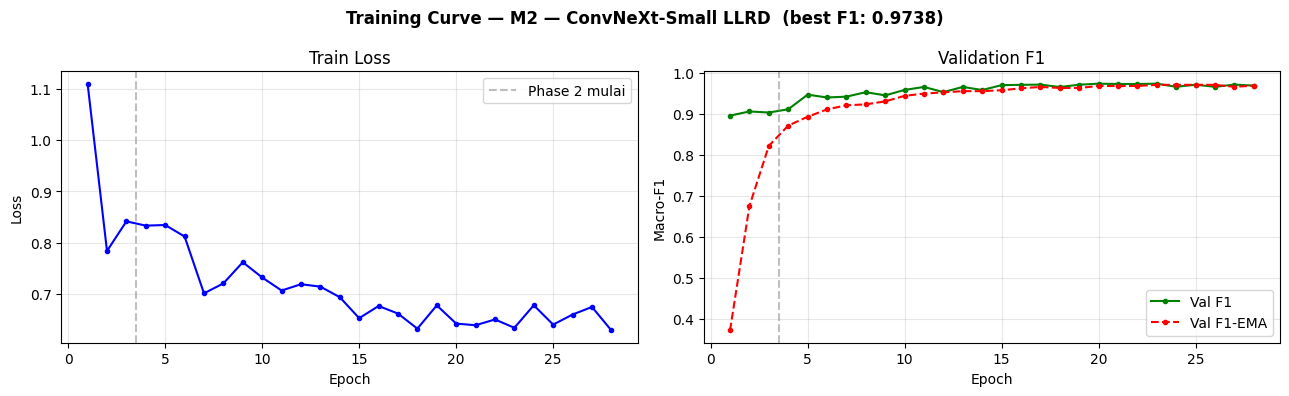

  Peak F1     : 0.9738
  Peak F1-EMA : 0.9710


In [18]:
plot_history(hist_m2, f'M2 — ConvNeXt-Small LLRD  (best F1: {best_f1_m2:.4f})')

In [19]:
# M3 — Swin-Small, resep standar
hist_m3, ckpt_m3, best_f1_m3 = train_full(MODEL_CONFIGS[2])


  m3_swin_small_std  |  resep: Standard  |  drop_path: 0.1


model.safetensors: reconstructing file:   0%|          |  0.00B /  200MB            

model.safetensors: downloading bytes:           |  0.00B            

  swin_small_patch4_window7_224.ms_in22k_ft_in1k  (48.8M param, drop_path=0.1)

  Phase 1 — head only (3 epoch)
    Trainable: 0.004M (head saja)
  Ep 01/3 | loss 1.0482 | F1 0.8990 | F1-EMA 0.5670
  Ep 02/3 | loss 0.7770 | F1 0.9234 | F1-EMA 0.8251
  Ep 03/3 | loss 0.8077 | F1 0.9242 | F1-EMA 0.8954

  Phase 2 — full fine-tune (25 epoch, Standard)
  Ep 01/25 | loss 0.7668 | F1 0.9456 | F1-EMA 0.9134 | best 0.9456 ✓
  Ep 02/25 | loss 0.7244 | F1 0.9425 | F1-EMA 0.9219 | best 0.9456
  Ep 03/25 | loss 0.6786 | F1 0.9669 | F1-EMA 0.9390 | best 0.9669 ✓
  Ep 04/25 | loss 0.6509 | F1 0.9581 | F1-EMA 0.9466 | best 0.9669
  Ep 05/25 | loss 0.6334 | F1 0.9549 | F1-EMA 0.9469 | best 0.9669
  Ep 06/25 | loss 0.6217 | F1 0.9427 | F1-EMA 0.9500 | best 0.9669
  Ep 07/25 | loss 0.6554 | F1 0.9629 | F1-EMA 0.9533 | best 0.9669
  Ep 08/25 | loss 0.5960 | F1 0.9592 | F1-EMA 0.9560 | best 0.9669
  Ep 09/25 | loss 0.6225 | F1 0.9614 | F1-EMA 0.9583 | best 0.9669
  Ep 10/25 | loss 0.6079 | F1 0.9631 | F1-

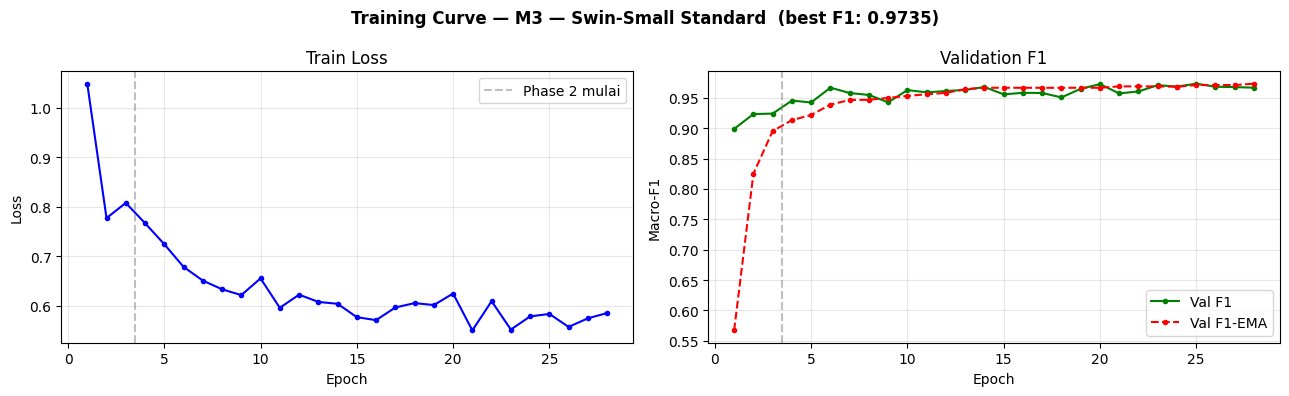

  Peak F1     : 0.9735
  Peak F1-EMA : 0.9735


In [20]:
plot_history(hist_m3, f'M3 — Swin-Small Standard  (best F1: {best_f1_m3:.4f})')

In [21]:
# M4 — Swin-Small, resep LLRD
hist_m4, ckpt_m4, best_f1_m4 = train_full(MODEL_CONFIGS[3])


  m4_swin_small_llrd  |  resep: LLRD  |  drop_path: 0.2
  swin_small_patch4_window7_224.ms_in22k_ft_in1k  (48.8M param, drop_path=0.2)

  Phase 1 — head only (3 epoch)
    Trainable: 0.004M (head saja)
  Ep 01/3 | loss 1.0859 | F1 0.8887 | F1-EMA 0.5273
  Ep 02/3 | loss 0.8641 | F1 0.9089 | F1-EMA 0.8468
  Ep 03/3 | loss 0.7747 | F1 0.9152 | F1-EMA 0.9046

  Phase 2 — full fine-tune (25 epoch, LLRD)
    LLRD via timm — 52 param groups


/tmp/ipykernel_2689/3191753487.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if scheduler: scheduler.step()


  Ep 01/25 | loss 0.7840 | F1 0.9278 | F1-EMA 0.9065 | best 0.9278 ✓
  Ep 02/25 | loss 0.7102 | F1 0.9370 | F1-EMA 0.9139 | best 0.9370 ✓
  Ep 03/25 | loss 0.7181 | F1 0.9582 | F1-EMA 0.9255 | best 0.9582 ✓
  Ep 04/25 | loss 0.7170 | F1 0.9603 | F1-EMA 0.9332 | best 0.9603 ✓
  Ep 05/25 | loss 0.6370 | F1 0.9586 | F1-EMA 0.9396 | best 0.9603
  Ep 06/25 | loss 0.6222 | F1 0.9639 | F1-EMA 0.9447 | best 0.9639 ✓
  Ep 07/25 | loss 0.6550 | F1 0.9561 | F1-EMA 0.9501 | best 0.9639
  Ep 08/25 | loss 0.6619 | F1 0.9634 | F1-EMA 0.9526 | best 0.9639
  Ep 09/25 | loss 0.6167 | F1 0.9609 | F1-EMA 0.9558 | best 0.9639
  Ep 10/25 | loss 0.6523 | F1 0.9629 | F1-EMA 0.9563 | best 0.9639
  Ep 11/25 | loss 0.6414 | F1 0.9677 | F1-EMA 0.9637 | best 0.9677 ✓
  Ep 12/25 | loss 0.6025 | F1 0.9614 | F1-EMA 0.9662 | best 0.9677
  Ep 13/25 | loss 0.5825 | F1 0.9609 | F1-EMA 0.9662 | best 0.9677
  Ep 14/25 | loss 0.6006 | F1 0.9555 | F1-EMA 0.9662 | best 0.9677
  Ep 15/25 | loss 0.5804 | F1 0.9584 | F1-EMA 0.96

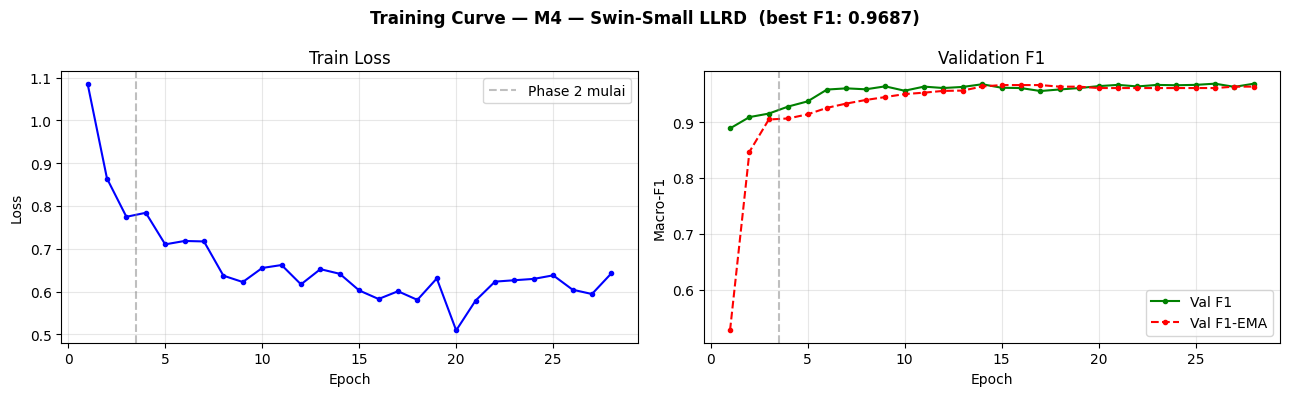

  Peak F1     : 0.9687
  Peak F1-EMA : 0.9662


In [22]:
plot_history(hist_m4, f'M4 — Swin-Small LLRD  (best F1: {best_f1_m4:.4f})')

In [23]:
# Muat checkpoint terbaik semua 4 model
def load_best(cfg, ckpt_path):
    """Muat model dari checkpoint terbaik ke DEVICE dalam mode eval."""
    drop = DROP_PATH_LLRD if cfg['llrd'] else DROP_PATH_STD
    m    = timm.create_model(cfg['name'], pretrained=False,
                             num_classes=NUM_CLASSES, drop_path_rate=drop)
    m.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return m.to(DEVICE).eval()


m1 = load_best(MODEL_CONFIGS[0], ckpt_m1)
m2 = load_best(MODEL_CONFIGS[1], ckpt_m2)
m3 = load_best(MODEL_CONFIGS[2], ckpt_m3)
m4 = load_best(MODEL_CONFIGS[3], ckpt_m4)
all_models = [m1, m2, m3, m4]
print('✅ Semua 4 checkpoint dimuat')

✅ Semua 4 checkpoint dimuat


In [24]:
# Performa tiap model secara individual
model_labels = ['M1 ConvNeXt-S Standard', 'M2 ConvNeXt-S LLRD',
                'M3 Swin-S Standard',      'M4 Swin-S LLRD']

print(f'{"Model":<30} {"Macro-F1":>10} {"Akurasi":>10}')
print('-' * 53)
for lbl, model in zip(model_labels, all_models):
    f1, acc = eval_epoch(model, val_loader)
    print(f'  {lbl:<28} {f1:>10.4f} {acc:>10.4f}')
print('-' * 53)
print(f'  {"Baseline NB07 (2× ConvNeXt-Tiny)":<28} {0.9844:>10.4f}')

Model                            Macro-F1    Akurasi
-----------------------------------------------------
  M1 ConvNeXt-S Standard           0.9683     0.9683
  M2 ConvNeXt-S LLRD               0.9738     0.9732
  M3 Swin-S Standard               0.9735     0.9732
  M4 Swin-S LLRD                   0.9687     0.9683
-----------------------------------------------------
  Baseline NB07 (2× ConvNeXt-Tiny)     0.9844


In [25]:
# Fungsi ensemble flat-average dan TTADataset (5-crop × flip H = 10 aug/gambar)

@torch.no_grad()
def eval_ensemble(models, loader):
    """Ensemble flat-average softmax tanpa TTA."""
    preds, truths = [], []
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        avg  = sum(torch.softmax(m(imgs), dim=1) for m in models) / len(models)
        preds.extend(avg.argmax(1).cpu().tolist())
        truths.extend(labels.tolist())
    f1  = f1_score(truths, preds, average='macro', zero_division=0)
    acc = sum(p == t for p, t in zip(preds, truths)) / len(truths)
    return f1, acc, preds, truths


class TTADataset(Dataset):
    """Resize(256) → FiveCrop(224) + flip H tiap crop = 10 tensor per gambar."""
    def __init__(self, folder):
        self.ds        = ImageFolder(folder)
        self.normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        path, label = self.ds.samples[idx]
        pil         = Image.open(path).convert('RGB')
        pil         = TF.resize(pil, RESIZE_SIZE)
        crops       = TF.five_crop(pil, IMG_SIZE)
        tensors     = []
        for c in crops:
            tensors.append(self.normalize(self.to_tensor(c)))
            tensors.append(self.normalize(self.to_tensor(TF.hflip(c))))
        return torch.stack(tensors), label   # [10, 3, 224, 224]


@torch.no_grad()
def eval_tta(models, val_folder, batch_size=8):
    """Ensemble dengan 10-crop TTA; kembalikan (f1, acc, preds, truths)."""
    loader = DataLoader(TTADataset(val_folder), batch_size=batch_size,
                        shuffle=False, num_workers=NUM_WORKERS)
    preds, truths = [], []
    for batch_imgs, labels in loader:
        B, N, C, H, W = batch_imgs.shape
        flat = batch_imgs.view(B * N, C, H, W).to(DEVICE)
        avg  = None
        for m in models:
            prob = torch.softmax(m(flat), dim=1).view(B, N, -1).mean(dim=1)
            avg  = prob if avg is None else avg + prob
        avg /= len(models)
        preds.extend(avg.argmax(1).cpu().tolist())
        truths.extend(labels.tolist())
    f1  = f1_score(truths, preds, average='macro', zero_division=0)
    acc = sum(p == t for p, t in zip(preds, truths)) / len(truths)
    return f1, acc, preds, truths


print('✅ eval_ensemble, TTADataset, eval_tta siap')

✅ eval_ensemble, TTADataset, eval_tta siap


In [26]:
# Bandingkan kombinasi ensemble tanpa TTA
print('Evaluasi kombinasi ensemble (tanpa TTA):\n')
print(f'{"Kombinasi":<42} {"Macro-F1":>10} {"Akurasi":>10}')
print('-' * 65)

combos = {}
for name, mdls in [
    ('M1+M2  (2× ConvNeXt-S)',            [m1, m2]),
    ('M3+M4  (2× Swin-S)',                [m3, m4]),
    ('M1+M3  (ConvNeXt-S + Swin-S std)',  [m1, m3]),
    ('M2+M4  (ConvNeXt-S + Swin-S llrd)', [m2, m4]),
    ('M1+M2+M3+M4  (4 model)',            all_models),
]:
    f1, acc, _, _ = eval_ensemble(mdls, val_loader)
    combos[name]  = (f1, mdls)
    print(f'  {name:<40} {f1:>10.4f} {acc:>10.4f}')

print('-' * 65)
best_key            = max(combos, key=lambda k: combos[k][0])
best_f1_c, best_mdls_c = combos[best_key]
print(f'  Terbaik: {best_key}  →  F1: {best_f1_c:.4f}')

Evaluasi kombinasi ensemble (tanpa TTA):

Kombinasi                                    Macro-F1    Akurasi
-----------------------------------------------------------------
  M1+M2  (2× ConvNeXt-S)                       0.9738     0.9732
  M3+M4  (2× Swin-S)                           0.9706     0.9707
  M1+M3  (ConvNeXt-S + Swin-S std)             0.9687     0.9683
  M2+M4  (ConvNeXt-S + Swin-S llrd)            0.9687     0.9683
  M1+M2+M3+M4  (4 model)                       0.9687     0.9683
-----------------------------------------------------------------
  Terbaik: M1+M2  (2× ConvNeXt-S)  →  F1: 0.9738


In [27]:
# Evaluasi dengan 10-crop TTA dan pilih konfigurasi final
print('Evaluasi dengan 10-crop TTA:\n')
print(f'{"Kombinasi":<42} {"Macro-F1":>10} {"Akurasi":>10}')
print('-' * 65)

tta_combos = {}
seen = set()
for name, mdls in [(f'TTA: {best_key}', best_mdls_c), ('TTA: M1+M2+M3+M4', all_models)]:
    key = tuple(id(m) for m in mdls)
    if key in seen: continue
    seen.add(key)
    f1, acc, _, _ = eval_tta(mdls, VAL_DIR)
    tta_combos[name] = (f1, mdls)
    print(f'  {name:<40} {f1:>10.4f} {acc:>10.4f}')

print('-' * 65)
best_tta_key            = max(tta_combos, key=lambda k: tta_combos[k][0])
best_f1_tta, best_mdls_tta = tta_combos[best_tta_key]
print(f'  Terbaik TTA: {best_tta_key}  →  F1: {best_f1_tta:.4f}')

USE_TTA = best_f1_tta > best_f1_c
if USE_TTA:
    FINAL_MODELS, FINAL_F1, FINAL_KEY = best_mdls_tta, best_f1_tta, best_tta_key
else:
    FINAL_MODELS, FINAL_F1, FINAL_KEY = best_mdls_c,   best_f1_c,   best_key
print(f'\n→ Gunakan TTA : {"YA" if USE_TTA else "TIDAK"}')
print(f'→ Konfigurasi : {FINAL_KEY}  |  F1: {FINAL_F1:.4f}')

Evaluasi dengan 10-crop TTA:

Kombinasi                                    Macro-F1    Akurasi
-----------------------------------------------------------------
  TTA: M1+M2  (2× ConvNeXt-S)                  0.9719     0.9732
  TTA: M1+M2+M3+M4                             0.9782     0.9780
-----------------------------------------------------------------
  Terbaik TTA: TTA: M1+M2+M3+M4  →  F1: 0.9782

→ Gunakan TTA : YA
→ Konfigurasi : TTA: M1+M2+M3+M4  |  F1: 0.9782


  Konfigurasi : TTA: M1+M2+M3+M4
  TTA         : Aktif (10-crop)
  Macro-F1    : 0.9782   (baseline NB07: 0.9844)
  Akurasi     : 0.9780
  Delta F1    : -0.0062

               precision    recall  f1-score   support

botol_plastik       0.97      0.99      0.98        78
gelas_plastik       0.94      1.00      0.97        78
kertas_kardus       0.96      1.00      0.98        54
saset_kemasan       1.00      0.95      0.97       100
    styrofoam       1.00      0.97      0.98       100

     accuracy                           0.98       410
    macro avg       0.98      0.98      0.98       410
 weighted avg       0.98      0.98      0.98       410



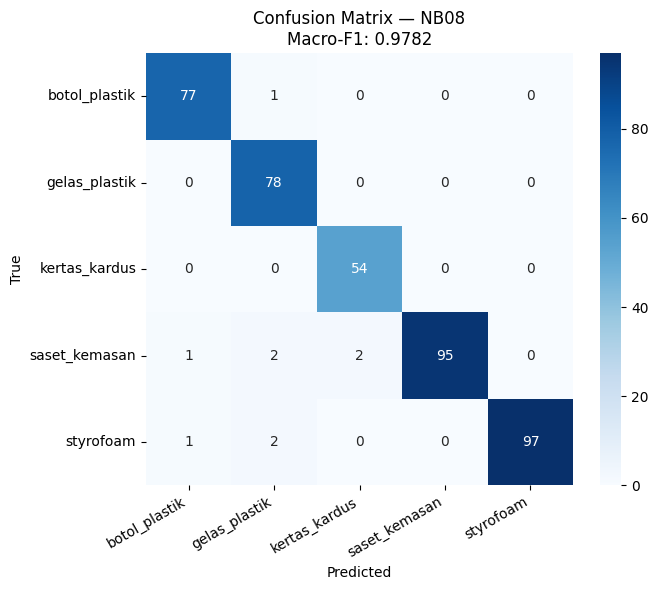

In [28]:
# Evaluasi final — classification report dan confusion matrix
if USE_TTA:
    f1_fin, acc_fin, final_preds, final_truths = eval_tta(FINAL_MODELS, VAL_DIR)
else:
    f1_fin, acc_fin, final_preds, final_truths = eval_ensemble(FINAL_MODELS, val_loader)

print('=' * 55)
print(f'  Konfigurasi : {FINAL_KEY}')
print(f'  TTA         : {"Aktif (10-crop)" if USE_TTA else "Tidak"}')
print(f'  Macro-F1    : {f1_fin:.4f}   (baseline NB07: 0.9844)')
print(f'  Akurasi     : {acc_fin:.4f}')
print(f'  Delta F1    : {f1_fin - 0.9844:+.4f}')
print('=' * 55)
print()
print(classification_report(final_truths, final_preds, target_names=CLASSES))

cm = confusion_matrix(final_truths, final_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix — NB08\nMacro-F1: {f1_fin:.4f}')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

In [29]:
# Kelas Ensemble untuk submission, simpan state_dict fp16

class Ensemble(nn.Module):
    """Flat-average ensemble — output log(avg softmax) [batch, 5]."""
    def __init__(self, members):
        super().__init__()
        self.members = nn.ModuleList(members)

    def forward(self, x):
        avg = torch.stack([torch.softmax(m(x), dim=1) for m in self.members]).mean(0)
        return torch.log(avg + 1e-8)


ensemble_save = Ensemble(FINAL_MODELS).eval().cpu()
state_fp16    = {k: v.half() if v.is_floating_point() else v
                 for k, v in ensemble_save.state_dict().items()}
PTH_PATH = os.path.join(SUBMISSION_DIR, 'model.pth')
torch.save(state_fp16, PTH_PATH)

print(f'✅ model.pth tersimpan → {PTH_PATH}')
print(f'   Ukuran  : {os.path.getsize(PTH_PATH) / 1e6:.1f} MB (fp16)')
print(f'   N model : {len(FINAL_MODELS)}')

✅ model.pth tersimpan → /content/submission_nb08/model.pth
   Ukuran  : 393.6 MB (fp16)
   N model : 4


In [30]:
# Generate model.py — kompatibel dengan evaluate.py dosen
id_to_cfg    = {id(m): cfg for m, cfg in zip(all_models, MODEL_CONFIGS)}
member_names = [id_to_cfg[id(m)]['name'] for m in FINAL_MODELS]
member_drops = [DROP_PATH_LLRD if id_to_cfg[id(m)]['llrd'] else DROP_PATH_STD for m in FINAL_MODELS]

lines = [
    '"""',
    'model.py — Submission NB08',
    f'Ensemble {len(member_names)} model:',
] + [f'  {i+1}. {n}  drop_path={d}' for i, (n, d) in enumerate(zip(member_names, member_drops))] + [
    'Urutan kelas (alfabetis ImageFolder):',
    '  0 botol_plastik  1 gelas_plastik  2 kertas_kardus  3 saset_kemasan  4 styrofoam',
    '"""',
    '',
    'import torch',
    'import torch.nn as nn',
    'from torchvision import transforms',
    'import timm',
    '',
    'NUM_CLASSES   = 5',
    'IMG_SIZE      = 224',
    'RESIZE_SIZE   = 256',
    'IMAGENET_MEAN = [0.485, 0.456, 0.406]',
    'IMAGENET_STD  = [0.229, 0.224, 0.225]',
    '',
    f'MEMBER_NAMES = {member_names}',
    f'MEMBER_DROPS = {member_drops}',
    '',
    '',
    'class Ensemble(nn.Module):',
    '    """Flat-average ensemble: rata-rata softmax semua anggota."""',
    '',
    '    def __init__(self, num_classes=NUM_CLASSES):',
    '        super().__init__()',
    '        self.members = nn.ModuleList([',
    '            timm.create_model(name, pretrained=False,',
    '                              num_classes=num_classes, drop_path_rate=dp)',
    '            for name, dp in zip(MEMBER_NAMES, MEMBER_DROPS)',
    '        ])',
    '',
    '    def forward(self, x):',
    '        avg = torch.stack([torch.softmax(m(x), dim=1) for m in self.members]).mean(0)',
    '        return torch.log(avg + 1e-8)',
    '',
    '',
    'def get_model():',
    '    """Kembalikan ensemble; bobot dimuat dari model.pth oleh evaluate.py."""',
    '    return Ensemble(num_classes=NUM_CLASSES)',
    '',
    '',
    'def get_transform():',
    '    """Transform inferensi: Resize(256) + CenterCrop(224) + normalisasi ImageNet."""',
    '    return transforms.Compose([',
    '        transforms.Resize(RESIZE_SIZE),',
    '        transforms.CenterCrop(IMG_SIZE),',
    '        transforms.ToTensor(),',
    '        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),',
    '    ])',
]

PY_PATH = os.path.join(SUBMISSION_DIR, 'model.py')
model_py = '\n'.join(lines) + '\n'
with open(PY_PATH, 'w') as f:
    f.write(model_py)
print(f'✅ model.py tersimpan → {PY_PATH}\n')
print('--- Isi model.py ---')
print(model_py)

✅ model.py tersimpan → /content/submission_nb08/model.py

--- Isi model.py ---
"""
model.py — Submission NB08
Ensemble 4 model:
  1. convnext_small.fb_in22k_ft_in1k  drop_path=0.1
  2. convnext_small.fb_in22k_ft_in1k  drop_path=0.2
  3. swin_small_patch4_window7_224.ms_in22k_ft_in1k  drop_path=0.1
  4. swin_small_patch4_window7_224.ms_in22k_ft_in1k  drop_path=0.2
Urutan kelas (alfabetis ImageFolder):
  0 botol_plastik  1 gelas_plastik  2 kertas_kardus  3 saset_kemasan  4 styrofoam
"""

import torch
import torch.nn as nn
from torchvision import transforms
import timm

NUM_CLASSES   = 5
IMG_SIZE      = 224
RESIZE_SIZE   = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

MEMBER_NAMES = ['convnext_small.fb_in22k_ft_in1k', 'convnext_small.fb_in22k_ft_in1k', 'swin_small_patch4_window7_224.ms_in22k_ft_in1k', 'swin_small_patch4_window7_224.ms_in22k_ft_in1k']
MEMBER_DROPS = [0.1, 0.2, 0.1, 0.2]


class Ensemble(nn.Module):
    """Flat-average ensemble: rata-rata 

In [31]:
# Simpan requirements.txt dan verifikasi submission (simulasi evaluate.py)
REQ_PATH = os.path.join(SUBMISSION_DIR, 'requirements.txt')
with open(REQ_PATH, 'w') as f:
    f.write('timm\n')
print(f'✅ requirements.txt tersimpan  (isi: timm)\n')

# Simulasi evaluate.py: get_model() → load_state_dict → forward → F1
print('Verifikasi submission (simulasi evaluate.py) ...')
spec = importlib.util.spec_from_file_location('model_sub', PY_PATH)
mod  = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

model_v = mod.get_model()
state_v = torch.load(PTH_PATH, map_location='cpu')
state_v = {k: v.float() if v.is_floating_point() else v for k, v in state_v.items()}
model_v.load_state_dict(state_v)
model_v = model_v.to(DEVICE).eval()
_       = mod.get_transform()

imgs_t, _ = next(iter(val_loader))
with torch.no_grad():
    out = model_v(imgs_t.to(DEVICE))
print(f'Output shape    : {tuple(out.shape)}  ← harus (batch, 5)')

f1_v, acc_v = eval_epoch(model_v, val_loader)
print(f'Macro-F1 verify : {f1_v:.4f}')
print(f'Akurasi verify  : {acc_v:.4f}')
print('\n✅ Submission valid — siap dipakai evaluate.py')

✅ requirements.txt tersimpan  (isi: timm)

Verifikasi submission (simulasi evaluate.py) ...
Output shape    : (32, 5)  ← harus (batch, 5)
Macro-F1 verify : 0.9712
Akurasi verify  : 0.9707

✅ Submission valid — siap dipakai evaluate.py


In [32]:
# Backup seluruh folder submission ke Google Drive
DRIVE_SUB = os.path.join(DRIVE_ROOT, 'submission_nb08')
if os.path.isdir(DRIVE_SUB):
    shutil.rmtree(DRIVE_SUB)
shutil.copytree(SUBMISSION_DIR, DRIVE_SUB)

print(f'✅ Backup ke Drive → {DRIVE_SUB}')
print('File tersimpan:')
for fname in sorted(os.listdir(DRIVE_SUB)):
    sz = os.path.getsize(os.path.join(DRIVE_SUB, fname))
    print(f'  {fname:<25} {sz / 1e6:>8.2f} MB')

✅ Backup ke Drive → /content/drive/MyDrive/submission_nb08
File tersimpan:
  __pycache__                   0.00 MB
  model.pth                   393.56 MB
  model.py                      0.00 MB
  requirements.txt              0.00 MB


In [33]:
# Ringkasan akhir
print('=' * 58)
print('  RINGKASAN NB08')
print('=' * 58)
print(f'  Baseline NB07   : 0.9844  (2× ConvNeXt-Tiny)')
print(f'  NB08 final      : {f1_fin:.4f}')
print(f'  Delta           : {f1_fin - 0.9844:+.4f}')
print(f'  TTA             : {"Aktif (10-crop)" if USE_TTA else "Tidak"}')
print()
print('  Model dalam ensemble:')
for i, (m, cfg) in enumerate(zip(FINAL_MODELS, MODEL_CONFIGS)):
    print(f'    {i+1}. {cfg["name"]}  [{"LLRD" if cfg["llrd"] else "Standard"}]')
print()
print('  Deliverable (Drive/submission_nb08/):')
for fname in sorted(os.listdir(DRIVE_SUB)):
    sz = os.path.getsize(os.path.join(DRIVE_SUB, fname))
    print(f'    {fname:<28} {sz / 1e6:>6.1f} MB')
print()
status = 'PASS ✅' if f1_fin > 0.9844 else 'PERLU CEK ⚠️'
print(f'  Target F1 > 0.9844 : {status}')
print('=' * 58)

  RINGKASAN NB08
  Baseline NB07   : 0.9844  (2× ConvNeXt-Tiny)
  NB08 final      : 0.9782
  Delta           : -0.0062
  TTA             : Aktif (10-crop)

  Model dalam ensemble:
    1. convnext_small.fb_in22k_ft_in1k  [Standard]
    2. convnext_small.fb_in22k_ft_in1k  [LLRD]
    3. swin_small_patch4_window7_224.ms_in22k_ft_in1k  [Standard]
    4. swin_small_patch4_window7_224.ms_in22k_ft_in1k  [LLRD]

  Deliverable (Drive/submission_nb08/):
    __pycache__                     0.0 MB
    model.pth                     393.6 MB
    model.py                        0.0 MB
    requirements.txt                0.0 MB

  Target F1 > 0.9844 : PERLU CEK ⚠️
